In [1]:
import pandas as pd

In [3]:
df=pd.read_csv("C:\\Users\\ADMIN\\OneDrive\\Desktop\\uber_data_analysis\\data\\raw\\uber-raw-data-apr14.csv")

In [5]:
df.head()

,Date/Time,Lat,Lon,Base
0,4/1/2014 0:11:00,40.7690,-73.9549,B02512
1,4/1/2014 0:17:00,40.7267,-74.0345,B02512
2,4/1/2014 0:21:00,40.7316,-73.9873,B02512
3,4/1/2014 0:28:00,40.7588,-73.9776,B02512
4,4/1/2014 0:33:00,40.7594,-73.9722,B02512


In [6]:
df.shape

(564516, 4)

In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 564516 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Date/Time  564516 non-null  str    
 1   Lat        564516 non-null  float64
 2   Lon        564516 non-null  float64
 3   Base       564516 non-null  str    
dtypes: float64(2), str(2)
memory usage: 29.9 MB


In [8]:
df.describe()

,Lat,Lon
count,564516.000000,564516.000000
mean,40.740005,-73.976817
std,0.036083,0.050426
min,40.072900,-74.773300
25%,40.722500,-73.997700
50%,40.742500,-73.984800
75%,40.760700,-73.970000
max,42.116600,-72.066600


In [9]:
df.isnull().sum()

Date/Time    0
Lat          0
Lon          0
Base         0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(7749)

In [13]:
df.columns

Index(['Date/Time', 'Lat', 'Lon', 'Base'], dtype='str')

In [15]:
duplicate_rows = df[df.duplicated()]
duplicate_rows.head(10)

,Date/Time,Lat,Lon,Base
44,4/1/2014 5:44:00,40.7430,-74.0301,B02512
128,4/1/2014 7:25:00,40.7805,-73.9481,B02512
185,4/1/2014 8:25:00,40.7620,-73.9787,B02512
190,4/1/2014 8:29:00,40.6904,-74.1778,B02512
238,4/1/2014 9:49:00,40.7195,-74.0367,B02512
265,4/1/2014 10:32:00,40.6949,-74.1781,B02512
291,4/1/2014 11:01:00,40.7883,-74.0456,B02512
299,4/1/2014 11:06:00,40.8275,-74.0468,B02512
345,4/1/2014 12:02:00,40.7852,-74.0220,B02512
349,4/1/2014 12:10:00,40.8289,-73.9451,B02512


In [16]:
df.columns

Index(['Date/Time', 'Lat', 'Lon', 'Base'], dtype='str')

In [17]:
df['Date/Time']=pd.to_datetime(df['Date/Time'])

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 564516 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Date/Time  564516 non-null  datetime64[us]
 1   Lat        564516 non-null  float64       
 2   Lon        564516 non-null  float64       
 3   Base       564516 non-null  str           
dtypes: datetime64[us](1), float64(2), str(1)
memory usage: 20.5 MB


In [20]:
df['Date/Time'].head()

0   2014-04-01 00:11:00
1   2014-04-01 00:17:00
2   2014-04-01 00:21:00
3   2014-04-01 00:28:00
4   2014-04-01 00:33:00
Name: Date/Time, dtype: datetime64[us]

In [19]:
df.columns

Index(['Date/Time', 'Lat', 'Lon', 'Base'], dtype='str')

In [22]:
df['hour'] = df['Date/Time'].dt.hour

In [24]:
df['day'] = df['Date/Time'].dt.day

In [23]:
df['day_name'] = df['Date/Time'].dt.day_name()

In [25]:
df['date'] = df['Date/Time'].dt.date

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 564516 entries, 0 to 564515
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Date/Time  564516 non-null  datetime64[us]
 1   Lat        564516 non-null  float64       
 2   Lon        564516 non-null  float64       
 3   Base       564516 non-null  str           
 4   hour       564516 non-null  int32         
 5   day_name   564516 non-null  str           
 6   day        564516 non-null  int32         
 7   date       564516 non-null  object        
dtypes: datetime64[us](1), float64(2), int32(2), object(1), str(2)
memory usage: 37.4+ MB


In [27]:
hourly_rides=df['hour'].value_counts().sort_index()
hourly_rides

hour
0     11910
1      7769
2      4935
3      5040
4      6095
5      9476
6     18498
7     24924
8     22843
9     17939
10    17865
11    18774
12    19425
13    22603
14    27190
15    35324
16    42003
17    45475
18    43003
19    38923
20    36244
21    36964
22    30645
23    20649
Name: count, dtype: int64

In [28]:
busiest_hour = hourly_rides.idxmax()

max_rides = hourly_rides.max()

print("Busiest Hour:", busiest_hour)
print("Total Rides:", max_rides)

Busiest Hour: 17
Total Rides: 45475


In [29]:
import matplotlib.pyplot as plt

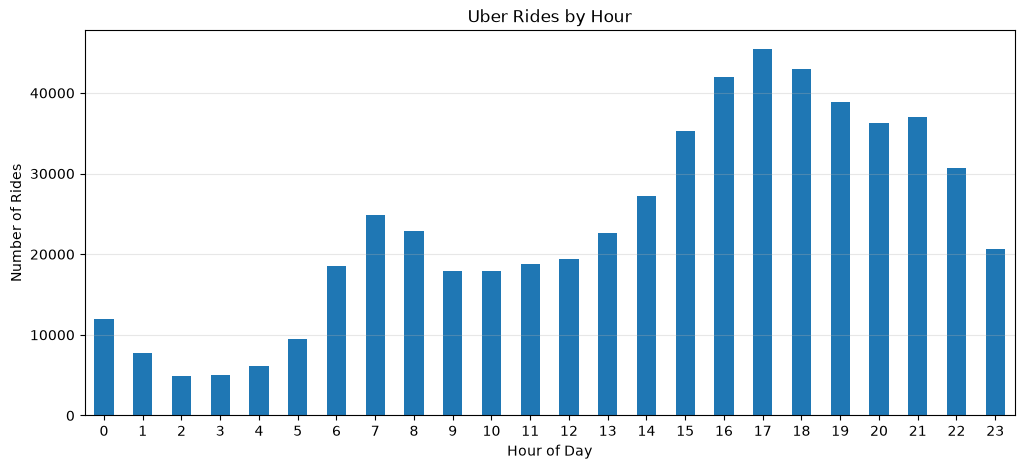

In [30]:
plt.figure(figsize=(12, 5))

hourly_rides.plot(kind='bar')

plt.title('Uber Rides by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Rides')

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [32]:
daily_rides = df['day_name'].value_counts()

daily_rides

day_name
Wednesday    108631
Tuesday       91185
Friday        90303
Thursday      85067
Saturday      77218
Monday        60861
Sunday        51251
Name: count, dtype: int64

In [33]:
busiest_day = daily_rides.idxmax()

max_daily_rides = daily_rides.max()

print("Busiest Day:", busiest_day)
print("Total Rides:", max_daily_rides)

Busiest Day: Wednesday
Total Rides: 108631


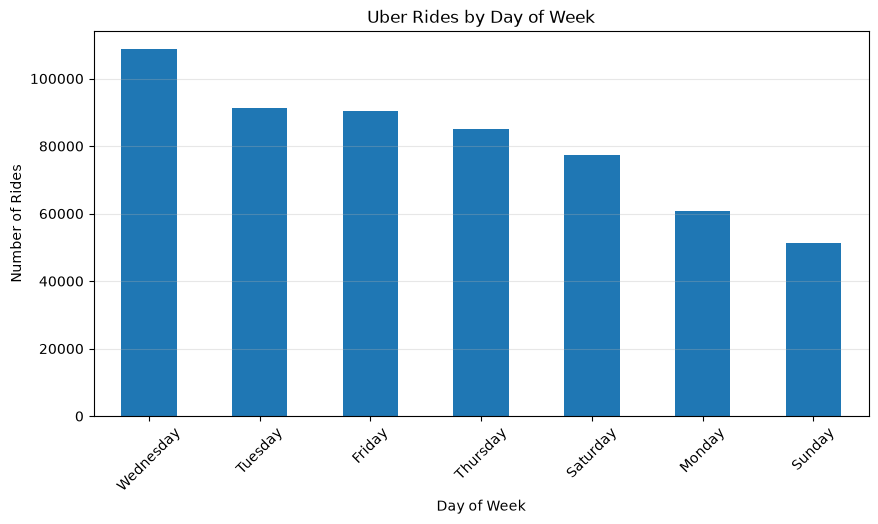

In [34]:
plt.figure(figsize=(10, 5))

daily_rides.plot(kind='bar')

plt.title('Uber Rides by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Rides')

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [36]:
daily_pickups = df['day'].value_counts().sort_index()

busiest_date = daily_pickups.idxmax()
max_pickups = daily_pickups.max()

print("Busiest Date:", busiest_date)
print("Total Pickups:", max_pickups)

Busiest Date: 30
Total Pickups: 36251


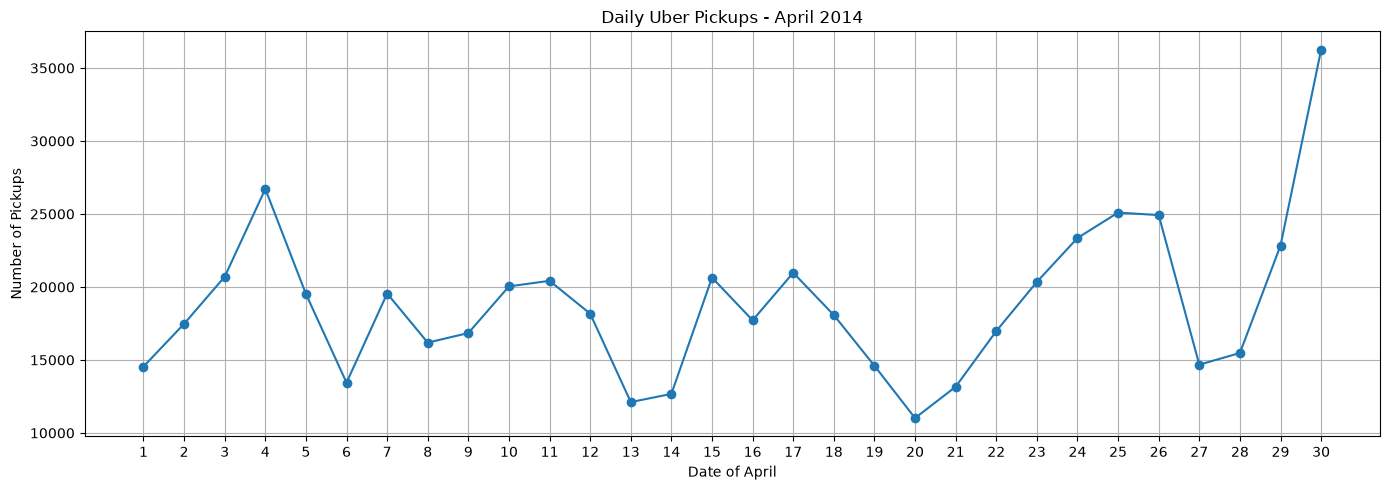

In [37]:
plt.figure(figsize=(14, 5))

daily_pickups.plot(kind='line', marker='o')

plt.title('Daily Uber Pickups - April 2014')
plt.xlabel('Date of April')
plt.ylabel('Number of Pickups')
plt.xticks(range(1, 31))
plt.grid(True)
plt.tight_layout()
plt.show()

In [38]:
print("Unique Latitudes:", df['Lat'].nunique())
print("Unique Longitudes:", df['Lon'].nunique())

print("\nLatitude Range:")
print(df['Lat'].min(), "to", df['Lat'].max())

print("\nLongitude Range:")
print(df['Lon'].min(), "to", df['Lon'].max())

Unique Latitudes: 4149
Unique Longitudes: 5621

Latitude Range:
40.0729 to 42.1166

Longitude Range:
-74.7733 to -72.0666


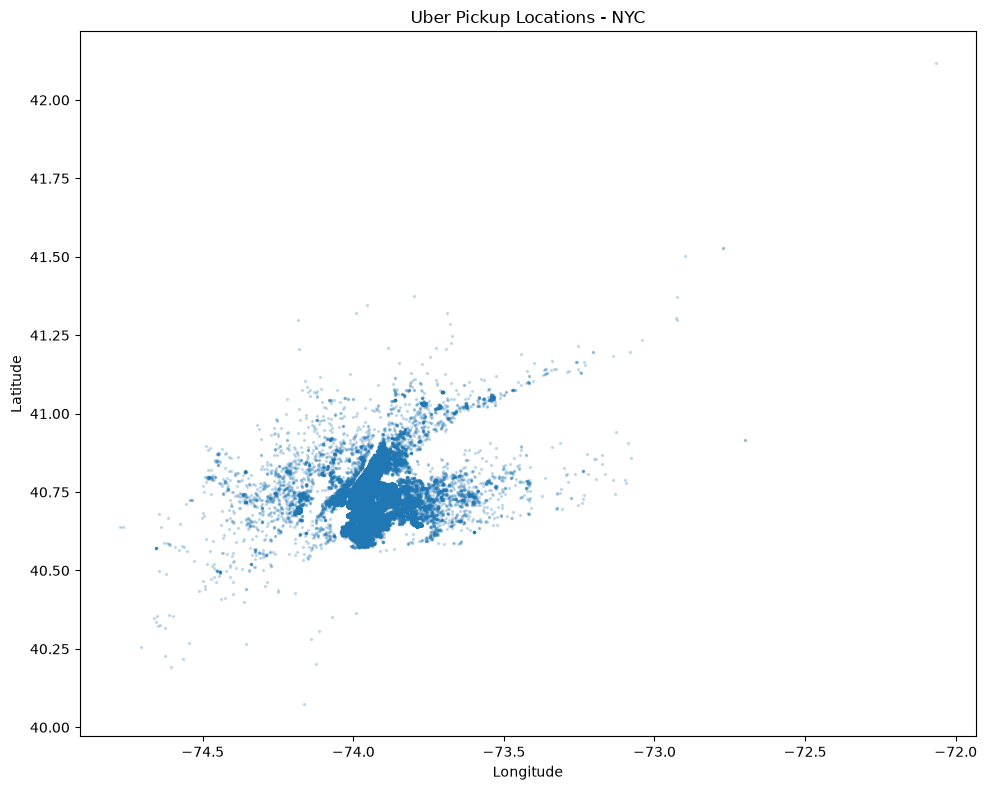

In [39]:
plt.figure(figsize=(10, 8))

plt.scatter(
    df['Lon'],
    df['Lat'],
    alpha=0.2,
    s=2
)

plt.title('Uber Pickup Locations - NYC')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.tight_layout()
plt.show()

In [41]:
df['Lat_Rounded'] = df['Lat'].round(2)
df['Lon_Rounded'] = df['Lon'].round(2)

top_locations = (
    df.groupby(['Lat_Rounded', 'Lon_Rounded'])
    .size()
    .reset_index(name='Total_Pickups')
    .sort_values(by='Total_Pickups', ascending=False)
)

top_locations.head(10)

,Lat_Rounded,Lon_Rounded,Total_Pickups
1112,40.76,-73.98,33123
1113,40.76,-73.97,30505
960,40.74,-73.99,26907
804,40.72,-74.00,23647
880,40.73,-74.00,22876
1038,40.75,-73.99,21753
1039,40.75,-73.98,20755
881,40.73,-73.99,19666
959,40.74,-74.00,18733
803,40.72,-74.01,15914


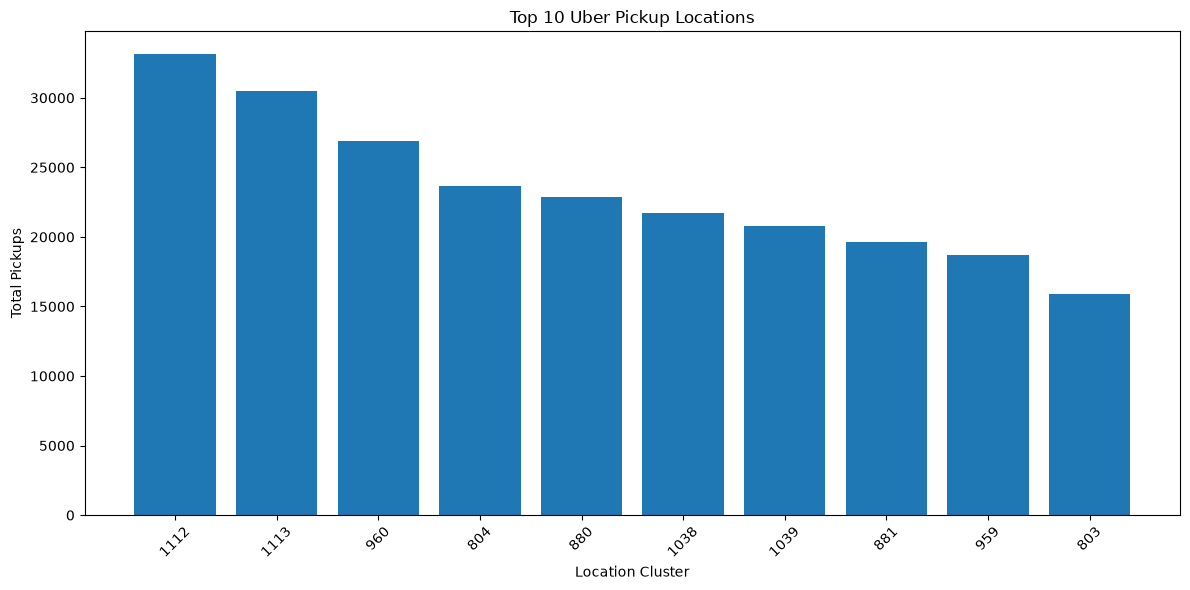

In [42]:
top_10 = top_locations.head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10.index.astype(str),
    top_10['Total_Pickups']
)

plt.title('Top 10 Uber Pickup Locations')
plt.xlabel('Location Cluster')
plt.ylabel('Total Pickups')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [43]:
base_pickups = df['Base'].value_counts()

print(base_pickups)


Base
B02682    227808
B02598    183263
B02617    108001
B02512     35536
B02764      9908
Name: count, dtype: int64


In [44]:
busiest_base = base_pickups.idxmax()
max_pickups = base_pickups.max()

print("Busiest Base:", busiest_base)
print("Total Pickups:", max_pickups)

Busiest Base: B02682
Total Pickups: 227808


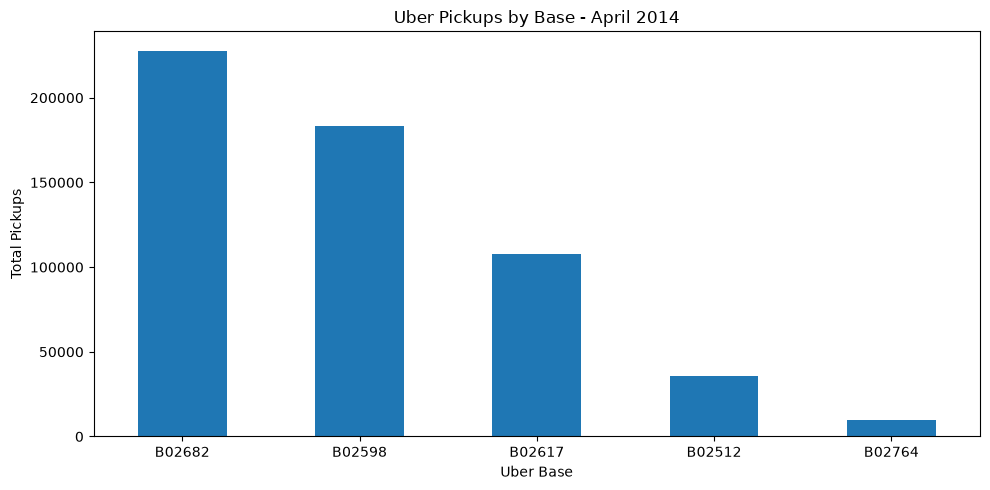

In [45]:
plt.figure(figsize=(10, 5))

base_pickups.plot(kind='bar')

plt.title('Uber Pickups by Base - April 2014')
plt.xlabel('Uber Base')
plt.ylabel('Total Pickups')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [46]:
import os
import matplotlib.pyplot as plt

# Create charts folder if it does not exist
os.makedirs('../outputs/charts', exist_ok=True)

# Save all existing charts again
for chart_name in plt.get_fignums():
    fig = plt.figure(chart_name)
    fig.savefig(
        f'../outputs/charts/chart_{chart_name}.png',
        dpi=300,
        bbox_inches='tight'
    )

print("Charts saved successfully!")


Charts saved successfully!


In [52]:

import os
import matplotlib.pyplot as plt

# Create charts folder
os.makedirs('../outputs/charts', exist_ok=True)

# 1. Hourly Pickups
plt.figure(figsize=(12, 5))
hourly_rides.plot(kind='bar')
plt.title('Uber Pickups by Hour')
plt.xlabel('Hour')
plt.ylabel('Total Pickups')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../outputs/charts/01_hourly_pickups.png', dpi=300)
plt.close()

# 2. Average Pickups by Weekday
daily_summary = df.groupby(['date', 'day_name']).size().reset_index(name='Rides')
average_daily_rides = daily_summary.groupby('day_name')['Rides'].mean()

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]
average_daily_rides = average_daily_rides.reindex(weekday_order)

plt.figure(figsize=(10, 5))
average_daily_rides.plot(kind='bar')
plt.title('Average Uber Pickups by Weekday')
plt.xlabel('Day')
plt.ylabel('Average Pickups')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/charts/02_average_weekday_pickups.png', dpi=300)
plt.close()

# 3. Daily Pickups
plt.figure(figsize=(14, 5))
daily_pickups.plot(kind='line', marker='o')
plt.title('Daily Uber Pickups - April 2014')
plt.xlabel('Date')
plt.ylabel('Total Pickups')
plt.xticks(range(1, 31))
plt.grid(True)
plt.tight_layout()
plt.savefig('../outputs/charts/03_daily_pickups.png', dpi=300)
plt.close()

# 4. Pickup Location Scatter Plot
plt.figure(figsize=(10, 8))
plt.scatter(df['Lon'], df['Lat'], alpha=0.2, s=2)
plt.title('Uber Pickup Locations - NYC')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.savefig('../outputs/charts/04_pickup_locations.png', dpi=300)
plt.close()

# 5. Top 10 Pickup Locations
top_10 = top_locations.head(10)

plt.figure(figsize=(12, 6))
plt.bar(
    [f"{lat}, {lon}" for lat, lon in
     zip(top_10['Lat_Rounded'], top_10['Lon_Rounded'])],
    top_10['Total_Pickups']
)
plt.title('Top 10 Uber Pickup Locations')
plt.xlabel('Location Coordinates')
plt.ylabel('Total Pickups')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/charts/05_top_10_locations.png', dpi=300)
plt.close()

# 6. Pickups by Base
plt.figure(figsize=(10, 5))
base_pickups.plot(kind='bar')
plt.title('Uber Pickups by Base - April 2014')
plt.xlabel('Uber Base')
plt.ylabel('Total Pickups')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(r'c:\Users\ADMIN\OneDrive\Desktop\uber_data_analysis\outputs\charts\06_pickups_by_base.png', dpi=300)
plt.close()

print("All charts saved successfully!")


All charts saved successfully!


In [53]:
print("Dataset shape:", df.shape)
print("\nDuplicate rows:", df.duplicated().sum())
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (564516, 10)

Duplicate rows: 7749

Missing values:
Date/Time      0
Lat            0
Lon            0
Base           0
hour           0
day_name       0
day            0
date           0
Lat_Rounded    0
Lon_Rounded    0
dtype: int64


In [54]:
original_columns = ['Date/Time', 'Lat', 'Lon', 'Base']

exact_duplicates = df.duplicated(
    subset=original_columns
).sum()

print("Exact duplicate records:", exact_duplicates)
print("Original dataset records:", len(df))

Exact duplicate records: 7749
Original dataset records: 564516


In [55]:
duplicate_counts = (
    df.groupby(['Date/Time', 'Lat', 'Lon', 'Base'])
    .size()
    .sort_values(ascending=False)
)

print("Highest duplicate frequency:")
print(duplicate_counts.head(10))

Highest duplicate frequency:
Date/Time            Lat      Lon       Base  
2014-04-19 19:58:00  40.7230  -73.9977  B02682    3
2014-04-20 20:18:00  40.6449  -73.7823  B02617    3
2014-04-28 05:31:00  40.6449  -73.7823  B02617    3
2014-04-30 22:57:00  40.7265  -74.0023  B02598    3
2014-04-03 07:58:00  40.7741  -73.8722  B02617    2
2014-04-02 19:20:00  40.7806  -73.9544  B02512    2
2014-04-02 16:54:00  40.7512  -74.0028  B02682    2
2014-04-11 15:43:00  40.7235  -73.9385  B02617    2
2014-04-06 15:24:00  40.7382  -73.9855  B02512    2
2014-04-08 07:54:00  40.7334  -73.9898  B02682    2
dtype: int64


In [56]:
# Keep original dataset unchanged
df_cleaned = df.drop_duplicates(
    subset=['Date/Time', 'Lat', 'Lon', 'Base']
).copy()

print("Original records:", len(df))
print("Cleaned records:", len(df_cleaned))
print("Removed records:", len(df) - len(df_cleaned))
print("Remaining duplicates:", df_cleaned.duplicated(
    subset=['Date/Time', 'Lat', 'Lon', 'Base']
).sum())

Original records: 564516
Cleaned records: 556767
Removed records: 7749
Remaining duplicates: 0


In [57]:
print("Latitude below 40.5:")
print(len(df_cleaned[df_cleaned['Lat'] < 40.5]))

print("\nLatitude above 41.0:")
print(len(df_cleaned[df_cleaned['Lat'] > 41.0]))

print("\nLongitude below -74.3:")
print(len(df_cleaned[df_cleaned['Lon'] < -74.3]))

print("\nLongitude above -73.5:")
print(len(df_cleaned[df_cleaned['Lon'] > -73.5]))

Latitude below 40.5:
58

Latitude above 41.0:
605

Longitude below -74.3:
424

Longitude above -73.5:
182


In [58]:
# Show records with unusual coordinates
unusual_locations = df_cleaned[
    (df_cleaned['Lat'] < 40.5) |
    (df_cleaned['Lat'] > 41.0) |
    (df_cleaned['Lon'] < -74.3) |
    (df_cleaned['Lon'] > -73.5)
]

print("Total unusual-location records:", len(unusual_locations))

unusual_locations[
    ['Date/Time', 'Lat', 'Lon', 'Base']
].head(20)

Total unusual-location records: 1168


,Date/Time,Lat,Lon,Base
391,2014-04-01 12:58:00,40.7790,-74.4200,B02512
427,2014-04-01 13:40:00,40.7757,-73.4202,B02512
459,2014-04-01 14:16:00,40.8056,-74.3923,B02512
740,2014-04-01 18:20:00,40.7829,-73.4372,B02512
1053,2014-04-02 05:32:00,40.7232,-74.4090,B02512
2913,2014-04-03 15:05:00,40.8152,-74.3590,B02512
3403,2014-04-03 19:30:00,40.7359,-74.3820,B02512
3633,2014-04-03 21:33:00,41.0214,-73.6269,B02512
3767,2014-04-03 22:44:00,40.7946,-74.4783,B02512
3874,2014-04-04 04:53:00,40.7252,-74.3443,B02512


In [59]:
nyc_area = df_cleaned[
    df_cleaned['Lat'].between(40.50, 41.00) &
    df_cleaned['Lon'].between(-74.30, -73.50)
].copy()

outside_area = df_cleaned[
    ~(
        df_cleaned['Lat'].between(40.50, 41.00) &
        df_cleaned['Lon'].between(-74.30, -73.50)
    )
]

print("Total cleaned records:", len(df_cleaned))
print("Inside study area:", len(nyc_area))
print("Outside study area:", len(outside_area))

Total cleaned records: 556767
Inside study area: 555599
Outside study area: 1168


In [60]:
import os

os.makedirs('../data/cleaned', exist_ok=True)

df_cleaned.to_csv(
    '../data/cleaned/uber_cleaned.csv',
    index=False
)

print("Cleaned dataset saved successfully!")
print("Total records:", len(df_cleaned))

Cleaned dataset saved successfully!
Total records: 556767


In [61]:
import os
import shutil

charts_folder = '../outputs/charts'
backup_folder = '../outputs/charts_backup'

if os.path.exists(charts_folder):
    shutil.copytree(
        charts_folder,
        backup_folder,
        dirs_exist_ok=True
    )

print("Old charts backed up successfully!")

Old charts backed up successfully!


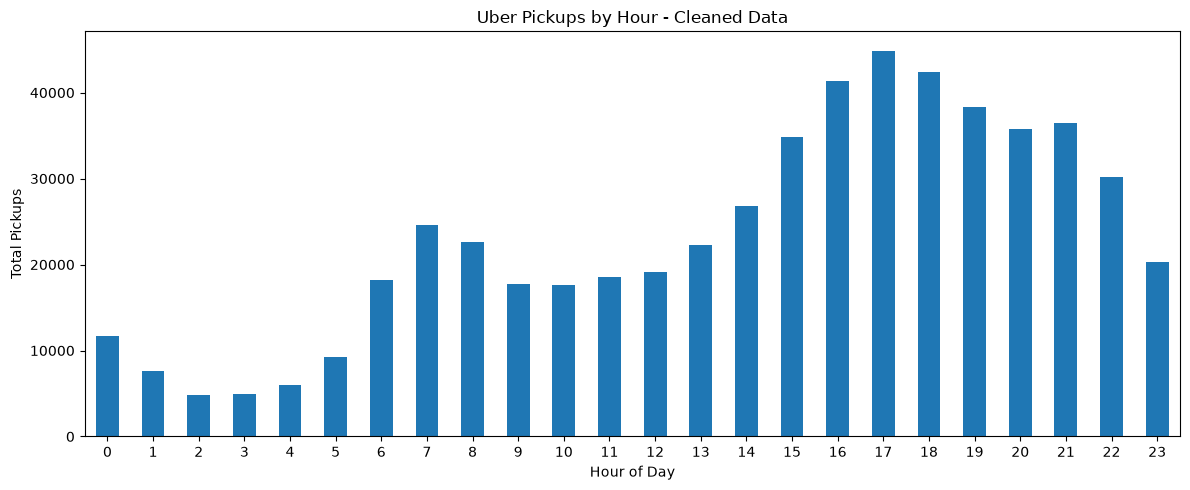

In [65]:
import matplotlib.pyplot as plt
import os

os.makedirs('../outputs/charts', exist_ok=True)

# Calculate hourly pickups from cleaned data
hourly_cleaned = df_cleaned['hour'].value_counts().sort_index()

# Create chart
plt.figure(figsize=(12, 5))
hourly_cleaned.plot(kind='bar')

plt.title('Uber Pickups by Hour - Cleaned Data')
plt.xlabel('Hour of Day')
plt.ylabel('Total Pickups')
plt.xticks(rotation=0)

plt.tight_layout()

# Save chart
plt.savefig(
    '../outputs/charts/01_hourly_pickups.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

In [63]:
print("Original hourly pickups:", df['hour'].value_counts().sum())
print("Cleaned hourly pickups:", df_cleaned['hour'].value_counts().sum())

print("\nOriginal busiest hour:")
print(df['hour'].value_counts().idxmax())

print("\nCleaned busiest hour:")
print(df_cleaned['hour'].value_counts().idxmax())

Original hourly pickups: 564516
Cleaned hourly pickups: 556767

Original busiest hour:
17

Cleaned busiest hour:
17


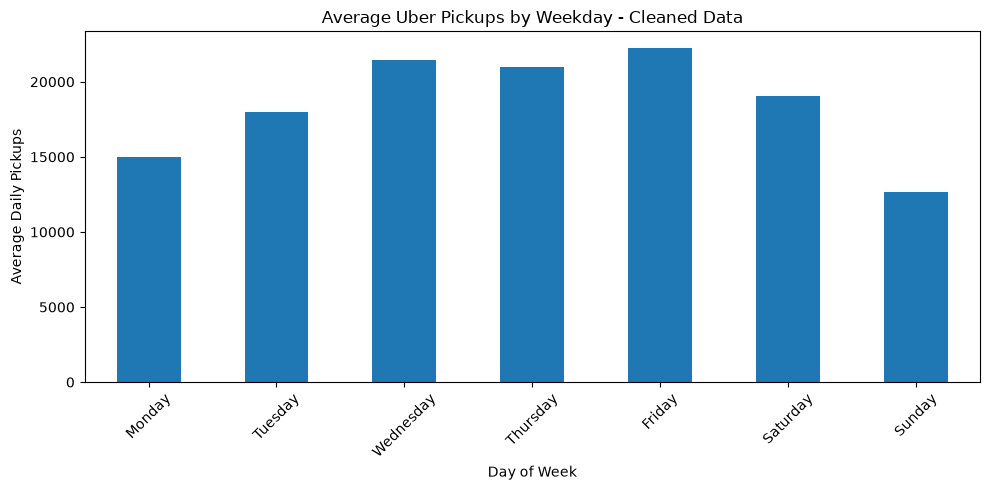

In [64]:
# Calculate average daily pickups
daily_summary_cleaned = (
    df_cleaned.groupby(['date', 'day_name'])
    .size()
    .reset_index(name='Pickups')
)

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

average_weekday_cleaned = (
    daily_summary_cleaned.groupby('day_name')['Pickups']
    .mean()
    .reindex(weekday_order)
)

# Create chart
plt.figure(figsize=(10, 5))

average_weekday_cleaned.plot(kind='bar')

plt.title('Average Uber Pickups by Weekday - Cleaned Data')
plt.xlabel('Day of Week')
plt.ylabel('Average Daily Pickups')
plt.xticks(rotation=45)

plt.tight_layout()

# Save chart
plt.savefig(
    '../outputs/charts/02_average_weekday_pickups.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

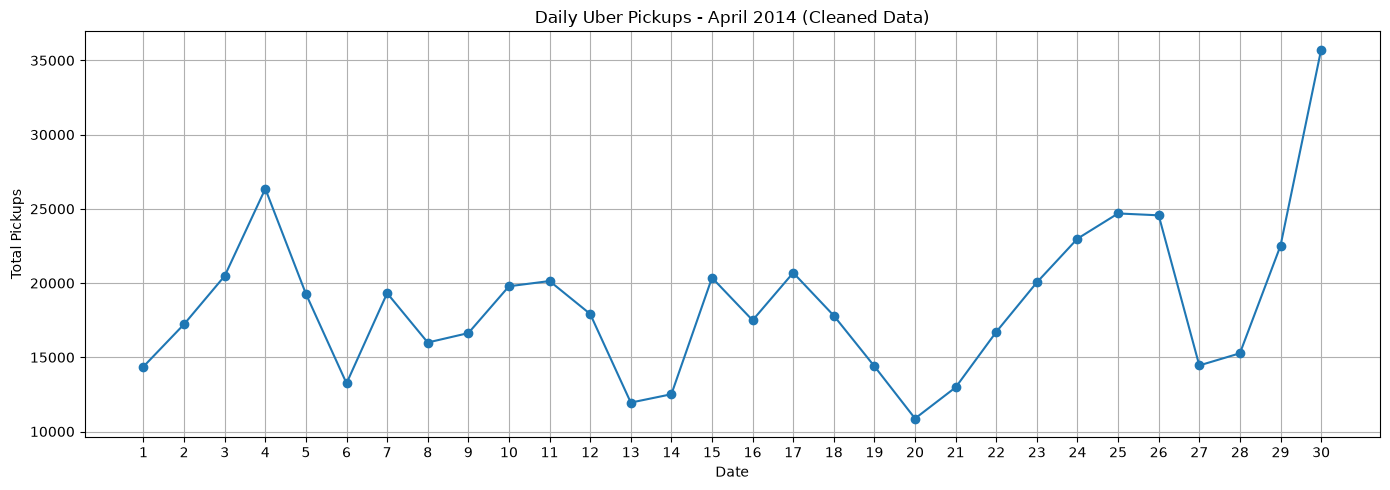

In [66]:
# Daily pickups from cleaned data
daily_cleaned = (
    df_cleaned.groupby('day')
    .size()
    .sort_index()
)

# Create chart
plt.figure(figsize=(14, 5))

daily_cleaned.plot(
    kind='line',
    marker='o'
)

plt.title('Daily Uber Pickups - April 2014 (Cleaned Data)')
plt.xlabel('Date')
plt.ylabel('Total Pickups')
plt.xticks(range(1, 31))
plt.grid(True)

plt.tight_layout()

# Save chart
plt.savefig(
    '../outputs/charts/03_daily_pickups.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

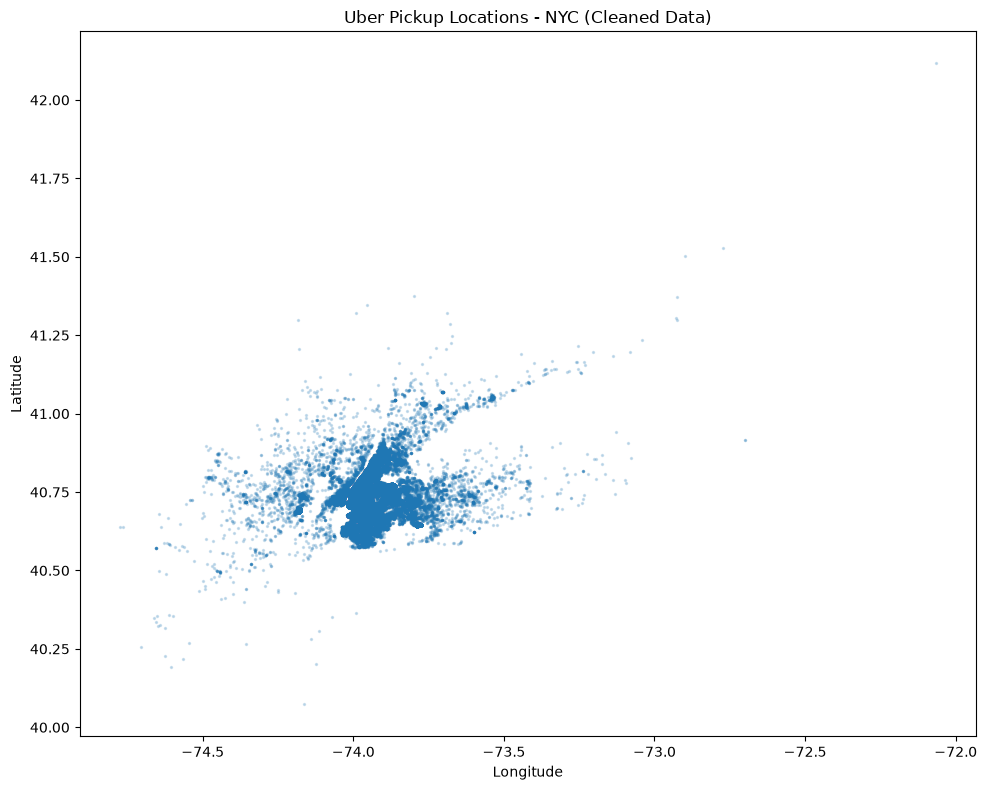

In [67]:
plt.figure(figsize=(10, 8))

plt.scatter(
    df_cleaned['Lon'],
    df_cleaned['Lat'],
    alpha=0.2,
    s=2
)

plt.title('Uber Pickup Locations - NYC (Cleaned Data)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/04_pickup_locations.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

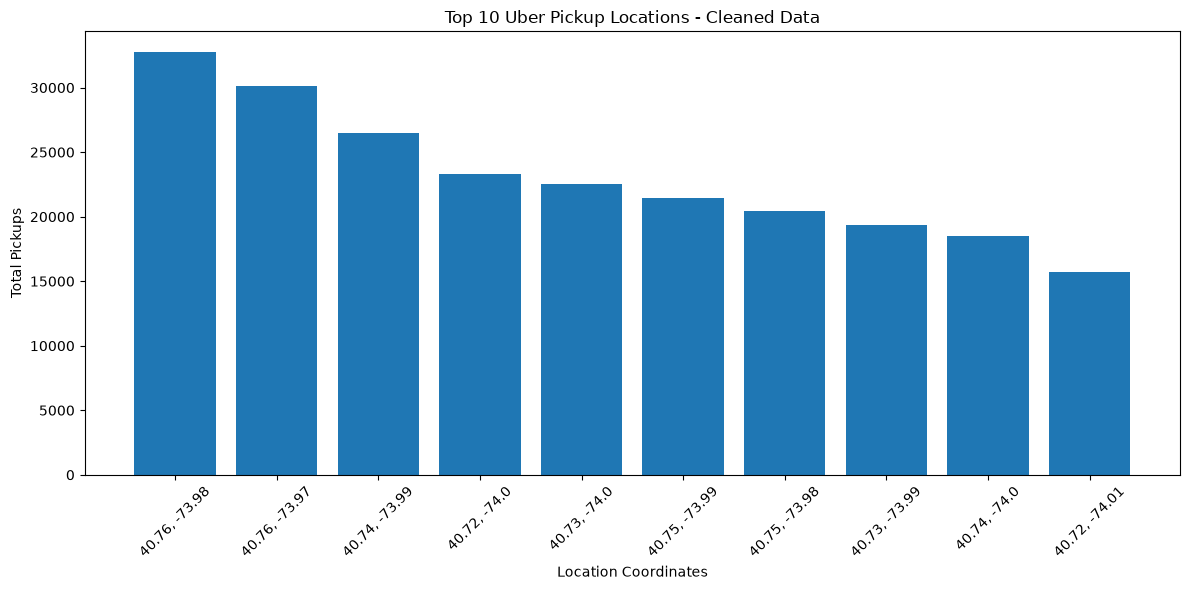

In [68]:
# Group cleaned data by rounded coordinates
top_locations_cleaned = (
    df_cleaned.groupby(['Lat_Rounded', 'Lon_Rounded'])
    .size()
    .reset_index(name='Total_Pickups')
    .sort_values(by='Total_Pickups', ascending=False)
)

top_10_cleaned = top_locations_cleaned.head(10)

# Create chart
plt.figure(figsize=(12, 6))

location_labels = (
    top_10_cleaned['Lat_Rounded'].astype(str)
    + ', '
    + top_10_cleaned['Lon_Rounded'].astype(str)
)

plt.bar(location_labels, top_10_cleaned['Total_Pickups'])

plt.title('Top 10 Uber Pickup Locations - Cleaned Data')
plt.xlabel('Location Coordinates')
plt.ylabel('Total Pickups')
plt.xticks(rotation=45)

plt.tight_layout()

# Save chart
plt.savefig(
    '../outputs/charts/05_top_10_locations.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

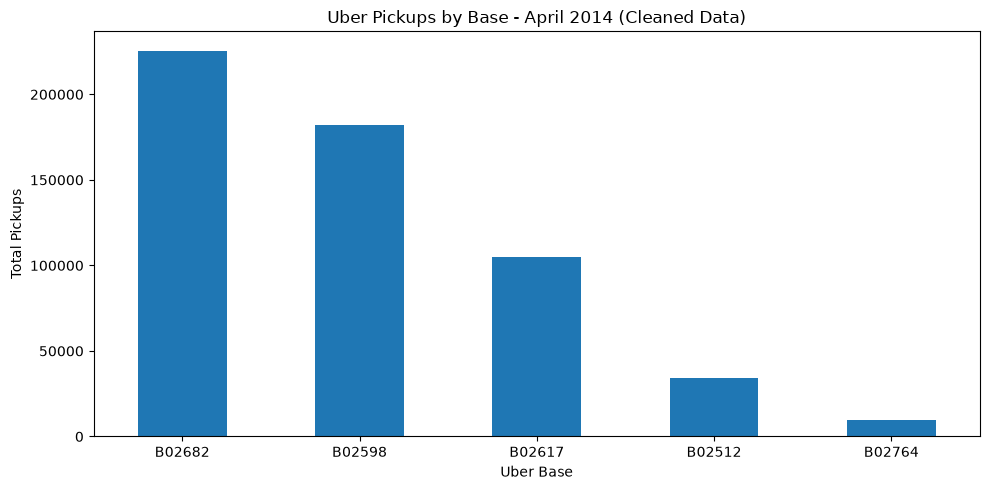

In [69]:
# Count pickups for each Uber Base
base_pickups_cleaned = df_cleaned['Base'].value_counts()

# Create chart
plt.figure(figsize=(10, 5))

base_pickups_cleaned.plot(kind='bar')

plt.title('Uber Pickups by Base - April 2014 (Cleaned Data)')
plt.xlabel('Uber Base')
plt.ylabel('Total Pickups')
plt.xticks(rotation=0)

plt.tight_layout()

# Save chart
plt.savefig(
    '../outputs/charts/06_pickups_by_base.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

In [70]:
import os

charts_folder = '../outputs/charts'

chart_files = sorted(os.listdir(charts_folder))

print("Total charts:", len(chart_files))

for chart in chart_files:
    print("✓", chart)

Total charts: 6
✓ 01_hourly_pickups.png
✓ 02_average_weekday_pickups.png
✓ 03_daily_pickups.png
✓ 04_pickup_locations.png
✓ 05_top_10_locations.png
✓ 06_pickups_by_base.png


In [71]:
import os

os.makedirs('../data/cleaned', exist_ok=True)

df_cleaned.to_csv(
    '../data/cleaned/uber_cleaned.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

print("Rows:", len(df_cleaned))
print("Columns:", len(df_cleaned.columns))
print("File exists:", os.path.exists('../data/cleaned/uber_cleaned.csv'))

Cleaned dataset saved successfully!
Rows: 556767
Columns: 10
File exists: True


In [72]:
cleaned_df = pd.read_csv('../data/cleaned/uber_cleaned.csv')

print("Dataset loaded successfully!")
print("Shape:", cleaned_df.shape)

print("\nFirst 5 rows:")
display(cleaned_df.head())

print("\nMissing values:")
print(cleaned_df.isnull().sum().sum())

Dataset loaded successfully!
Shape: (556767, 10)

First 5 rows:


,Date/Time,Lat,Lon,Base,hour,day_name,day,date,Lat_Rounded,Lon_Rounded
0,2014-04-01 00:11:00,40.7690,-73.9549,B02512,0,Tuesday,1,2014-04-01,40.77,-73.95
1,2014-04-01 00:17:00,40.7267,-74.0345,B02512,0,Tuesday,1,2014-04-01,40.73,-74.03
2,2014-04-01 00:21:00,40.7316,-73.9873,B02512,0,Tuesday,1,2014-04-01,40.73,-73.99
3,2014-04-01 00:28:00,40.7588,-73.9776,B02512,0,Tuesday,1,2014-04-01,40.76,-73.98
4,2014-04-01 00:33:00,40.7594,-73.9722,B02512,0,Tuesday,1,2014-04-01,40.76,-73.97



Missing values:
0


In [73]:
import pandas as pd

df_check = pd.read_csv('../data/cleaned/uber_cleaned.csv')

print("Dataset shape:", df_check.shape)
print("\nColumns:")
print(df_check.columns.tolist())

print("\nTotal missing values:", df_check.isnull().sum().sum())
print("Total duplicate rows:", df_check.duplicated().sum())

Dataset shape: (556767, 10)

Columns:
['Date/Time', 'Lat', 'Lon', 'Base', 'hour', 'day_name', 'day', 'date', 'Lat_Rounded', 'Lon_Rounded']

Total missing values: 0
Total duplicate rows: 0
